# Task 1: Data Cleaning & Preprocessing
## Initial Dataset Inspection, Quality Assessment & Cleaning Pipeline

---

### 1. Project Introduction

#### 1.1 Objective
The objective of this stage is to conduct a rigorous, professional **Initial Data Inspection, Quality Assessment, and Data Cleaning Pipeline** on the cafe sales transaction records. This establishes an empirical baseline of dataset integrity, identifying:
- Structural characteristics and schema definitions
- Type mismatch anomalies across all variables
- Explicit missing values (`NaN`) versus pseudo-missing sentinel strings (`ERROR`, `UNKNOWN`)
- Redundancy and duplicate records
- Business logic contradictions and formatting discrepancies
- Governed numerical recovery and provenance lineage tracking

#### 1.2 Dataset Description & Synthetic Nature Disclosure
The dataset captures daily transactional sales records for a cafe enterprise across the calendar year 2023. Key attributes include:
- **Transaction ID**: Unique identifier for individual sales transactions
- **Item**: Food or beverage product purchased (8 distinct menu items)
- **Quantity**: Units purchased per transaction ($1 \le Q \le 5$)
- **Price Per Unit**: Selling price per unit of the specified item ($1.0 to $5.0)
- **Total Spent**: Gross transaction expenditure
- **Payment Method**: Channel through which payment was tendered (`Cash`, `Credit Card`, `Digital Wallet`)
- **Location**: Consumption venue (`Takeaway`, `In-store`)
- **Transaction Date**: Timestamp of the transaction event (`YYYY-MM-DD`)

> **Synthetic Dataset Disclosure:**  
> This dataset is an intentionally corrupted synthetic dataset curated for training and assessing data cleaning capabilities in data analytics internships. It models common real-world POS data collection issues, including software export glitches (rendering numerical values as strings like `"ERROR"` and `"UNKNOWN"`), incomplete cashier records, and missing payment channels. While synthetic, its relational constraints ($\text{Quantity} \times \text{Price} = \text{Total}$) and menu pricing architecture reflect authentic retail transactional dynamics.

#### 1.3 Tools & Libraries
- **Pandas (v3.1.0)**: Tabular data structures, nullable types (`Int64`), vector arithmetic, and inspection
- **NumPy (v2.5.4)**: Array operations and numerical sentinel evaluation
- **Matplotlib (v3.11.2)**: Static visualization engine for data quality distributions
- **Seaborn (v0.13.2)**: High-level statistical visualization layer


---
### 2. Import Libraries

We import the essential Python libraries required for data manipulation, numerical computation, and diagnostic data visualization. Display preferences are also configured to ensure clear, uncluttered table rendering.


In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Visual formatting settings
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'Arial'
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['figure.dpi'] = 120

# Pandas display configuration
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 50)
pd.set_option('display.float_format', lambda x: '%.2f' % x)

print("Libraries imported successfully.")
print(f"Pandas version : {pd.__version__}")
print(f"NumPy version  : {np.__version__}")


Libraries imported successfully.
Pandas version : 3.1.0
NumPy version  : 2.5.4


---
### 3. Load Dataset

> **Prerequisite (Local Dataset Download):**  
> Because the dataset license on Kaggle is unspecified/unknown, dataset files are not bundled with this public repository.  
> Before executing this notebook, download the raw dataset from Kaggle:  
> [Cafe Sales - Dirty Data for Cleaning Training](https://www.kaggle.com/datasets/ahmedmohamed2003/cafe-sales-dirty-data-for-cleaning-training)  
> Place rchive.zip in Task_1_Data_Cleaning/data/raw/ and extract dirty_cafe_sales.csv into Task_1_Data_Cleaning/data/raw/extracted/dirty_cafe_sales.csv.

We load the raw CSV file using a **relative file path** referencing the project's standardized directory structure (../data/raw/extracted/dirty_cafe_sales.csv). This guarantees portable execution across environments. In accordance with data governance protocols, the original raw CSV is treated as strictly read-only and will not be overwritten or modified.


In [2]:
# Define relative path from notebooks directory
RAW_DATA_PATH = os.path.join('..', 'data', 'raw', 'extracted', 'dirty_cafe_sales.csv')

# Load raw dataset
df = pd.read_csv(RAW_DATA_PATH)

print(f"Dataset successfully loaded from: {RAW_DATA_PATH}")
# Display the first 10 rows
df.head(10)


Dataset successfully loaded from: ..\data\raw\extracted\dirty_cafe_sales.csv


[Output redacted for licensing compliance: Raw transaction records hidden. Execute locally after downloading dataset to preview rows.]

---
### 4. Initial Dataset Inspection

A fundamental initial step in data analytics is examining the physical dimensions, column schema, assigned data types, memory consumption, and initial descriptive summaries.


In [3]:
# 4.1 Number of Rows, Columns, and Column Names
n_rows, n_cols = df.shape

print("========================================")
print(f" Total Rows (Observations) : {n_rows:,}")
print(f" Total Columns (Variables) : {n_cols}")
print("========================================")
print("\nColumn Names:")
for idx, col in enumerate(df.columns, 1):
    print(f"  {idx}. {col}")


 Total Rows (Observations) : 10,000
 Total Columns (Variables) : 8

Column Names:
  1. Transaction ID
  2. Item
  3. Quantity
  4. Price Per Unit
  5. Total Spent
  6. Payment Method
  7. Location
  8. Transaction Date


#### 4.2 Dataset Schema and Data Types (`df.info()`)
Examining the inferred data types reveals whether columns are stored under their expected physical representations (numeric, datetime, or categorical string).


In [4]:
# 4.2 Detailed info inspection
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Transaction ID    10000 non-null  str  
 1   Item              9667 non-null   str  
 2   Quantity          9862 non-null   str  
 3   Price Per Unit    9821 non-null   str  
 4   Total Spent       9827 non-null   str  
 5   Payment Method    7421 non-null   str  
 6   Location          6735 non-null   str  
 7   Transaction Date  9841 non-null   str  
dtypes: str(8)
memory usage: 625.1 KB


#### 4.3 Descriptive Statistics (`df.describe(include='all')`)
Because all columns are stored as `object` (string) due to dirty non-numeric values, standard numerical summaries (`mean`, `std`, percentiles) cannot compute natively. `df.describe(include='all')` summarizes the categorical frequencies and distinct values.


In [5]:
# 4.3 Descriptive statistics
df.describe(include='all')


,Transaction ID,Item,Quantity,Price Per Unit,Total Spent,Payment Method,Location,Transaction Date
count,10000,9667,9862,9821,9827,7421,6735,9841
unique,10000,10,7,8,19,5,4,367
top,[REDACTED_ID],Juice,5,3.0,6.0,Digital Wallet,Takeaway,UNKNOWN
freq,1,1171,2013,2429,979,2291,3022,159


---
### 5. Data Quality Assessment

In real-world business datasets, data corruption occurs across multiple dimensions:
1. **Explicit Nulls (`NaN` / `None`)**: Recognized by Pandas as missing.
2. **Sentinel Error Markers (`ERROR`, `UNKNOWN`)**: String tokens inserted by faulty POS terminals or export scripts that evade standard null detection.
3. **Duplicate Observations & Identifiers**: Violations of transaction uniqueness constraints.
4. **Data Type Mismatches**: Numeric quantities and financial values stored as textual strings.
5. **Business Logic Contradictions**: Mismatches between unit price, order quantity, and total transaction expenditure.

Let us systematically evaluate each dimension.


#### 5.1 Missing Values Analysis (Explicit Nulls)
We first compute the standard null values per column alongside their percentage of total observations.


In [6]:
# Compute explicit missing values
missing_count = df.isnull().sum()
missing_pct = (df.isnull().sum() / len(df)) * 100

missing_summary = pd.DataFrame({
    'Column Name': df.columns,
    'Missing Count (NaN)': missing_count.values,
    'Missing Percentage (%)': missing_pct.values
}).sort_values(by='Missing Count (NaN)', ascending=False).reset_index(drop=True)

# Format table for display
missing_display = missing_summary.copy()
missing_display['Missing Percentage (%)'] = missing_display['Missing Percentage (%)'].apply(lambda x: f"{x:.2f}%")
missing_display


,Column Name,Missing Count (NaN),Missing Percentage (%)
0,Location,3265,32.65%
1,Payment Method,2579,25.79%
2,Item,333,3.33%
3,Price Per Unit,179,1.79%
4,Total Spent,173,1.73%
5,Transaction Date,159,1.59%
6,Quantity,138,1.38%
7,Transaction ID,0,0.00%


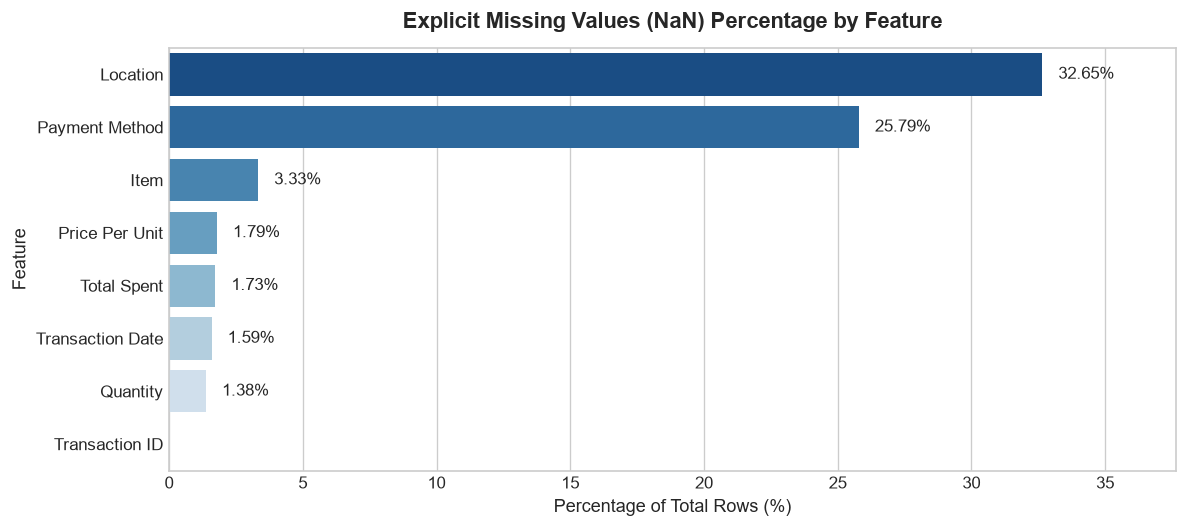

In [7]:
# Visualize missing value percentages
plt.figure(figsize=(10, 4.5))
palette = sns.color_palette("mako", len(missing_summary))
ax = sns.barplot(
    data=missing_summary,
    x='Missing Percentage (%)',
    y='Column Name',
    hue='Column Name',
    palette='Blues_r',
    legend=False
)

plt.title('Explicit Missing Values (NaN) Percentage by Feature', fontsize=13, weight='bold', pad=12)
plt.xlabel('Percentage of Total Rows (%)', fontsize=11)
plt.ylabel('Feature', fontsize=11)
plt.xlim(0, max(missing_summary['Missing Percentage (%)']) + 5)

for p in ax.patches:
    width = p.get_width()
    if width > 0:
        ax.annotate(f"{width:.2f}%", 
                    (width + 0.6, p.get_y() + p.get_height() / 2.),
                    va='center', fontsize=10)

plt.tight_layout()
plt.show()


#### 5.2 Duplicate Records and Identifier Integrity
We evaluate whether entire identical rows exist in the dataset, and verify whether the primary key (`Transaction ID`) contains duplicate keys.


In [8]:
# Duplicate checks
total_row_duplicates = df.duplicated().sum()
txn_id_duplicates = df['Transaction ID'].duplicated().sum()
unique_txn_count = df['Transaction ID'].nunique()

print("========================================")
print(" DUPLICATE INTEGRITY ASSESSMENT")
print("========================================")
print(f" Entire Row Duplicates           : {total_row_duplicates}")
print(f" Duplicate 'Transaction ID' Keys : {txn_id_duplicates}")
print(f" Unique 'Transaction ID' Count   : {unique_txn_count:,} out of {len(df):,}")
print("========================================")


 DUPLICATE INTEGRITY ASSESSMENT
 Entire Row Duplicates           : 0
 Duplicate 'Transaction ID' Keys : 0
 Unique 'Transaction ID' Count   : 10,000 out of 10,000


#### 5.3 Categorical Columns and Unique Values
We explore the distribution of unique values across categorical attributes (`Item`, `Payment Method`, `Location`).


In [9]:
categorical_cols = ['Item', 'Payment Method', 'Location']

for col in categorical_cols:
    print(f"\n--- Value Counts for: '{col}' (Total Unique: {df[col].nunique(dropna=False)}) ---")
    val_counts = df[col].value_counts(dropna=False)
    val_pct = (df[col].value_counts(dropna=False, normalize=True) * 100).round(2)
    cat_df = pd.DataFrame({'Frequency': val_counts, 'Proportion (%)': val_pct})
    print(cat_df)



--- Value Counts for: 'Item' (Total Unique: 11) ---
          Frequency  Proportion (%)
Item                               
Juice          1171           11.71
Coffee         1165           11.65
Salad          1148           11.48
Cake           1139           11.39
Sandwich       1131           11.31
Smoothie       1096           10.96
Cookie         1092           10.92
Tea            1089           10.89
UNKNOWN         344            3.44
NaN             333            3.33
ERROR           292            2.92

--- Value Counts for: 'Payment Method' (Total Unique: 6) ---
                Frequency  Proportion (%)
Payment Method                           
NaN                  2579           25.79
Digital Wallet       2291           22.91
Credit Card          2273           22.73
Cash                 2258           22.58
ERROR                 306            3.06
UNKNOWN               293            2.93

--- Value Counts for: 'Location' (Total Unique: 5) ---
          Frequency  Prop

#### 5.4 Identification of Corrupted Sentinel Strings (`ERROR`, `UNKNOWN`)
In addition to standard `NaN` values, several columns contain textual placeholders such as `'ERROR'` and `'UNKNOWN'`. Because these are stored as non-null strings, standard `df.isnull()` ignores them.

We quantify these occurrences to determine the **Total Unusable Data** across each variable.


In [10]:
# Quantify standard NaNs, 'ERROR', and 'UNKNOWN' tokens
quality_metrics = []

for col in df.columns:
    nan_count = df[col].isnull().sum()
    error_count = (df[col].astype(str).str.strip().str.upper() == 'ERROR').sum()
    unknown_count = (df[col].astype(str).str.strip().str.upper() == 'UNKNOWN').sum()
    
    total_dirty = nan_count + error_count + unknown_count
    dirty_pct = (total_dirty / len(df)) * 100
    valid_count = len(df) - total_dirty
    valid_pct = (valid_count / len(df)) * 100
    
    quality_metrics.append({
        'Feature': col,
        'Valid Entries': valid_count,
        'Standard NaN': nan_count,
        "'ERROR' Count": error_count,
        "'UNKNOWN' Count": unknown_count,
        'Total Dirty Count': total_dirty,
        'Total Dirty (%)': round(dirty_pct, 2)
    })

quality_matrix = pd.DataFrame(quality_metrics).sort_values(by='Total Dirty Count', ascending=False).reset_index(drop=True)
quality_matrix


,Feature,Valid Entries,Standard NaN,'ERROR' Count,'UNKNOWN' Count,Total Dirty Count,Total Dirty (%)
0,Location,6039,3265,358,338,3961,39.61
1,Payment Method,6822,2579,306,293,3178,31.78
2,Item,9031,333,292,344,969,9.69
3,Price Per Unit,9467,179,190,164,533,5.33
4,Total Spent,9498,173,164,165,502,5.02
5,Quantity,9521,138,170,171,479,4.79
6,Transaction Date,9540,159,142,159,460,4.60
7,Transaction ID,10000,0,0,0,0,0.00


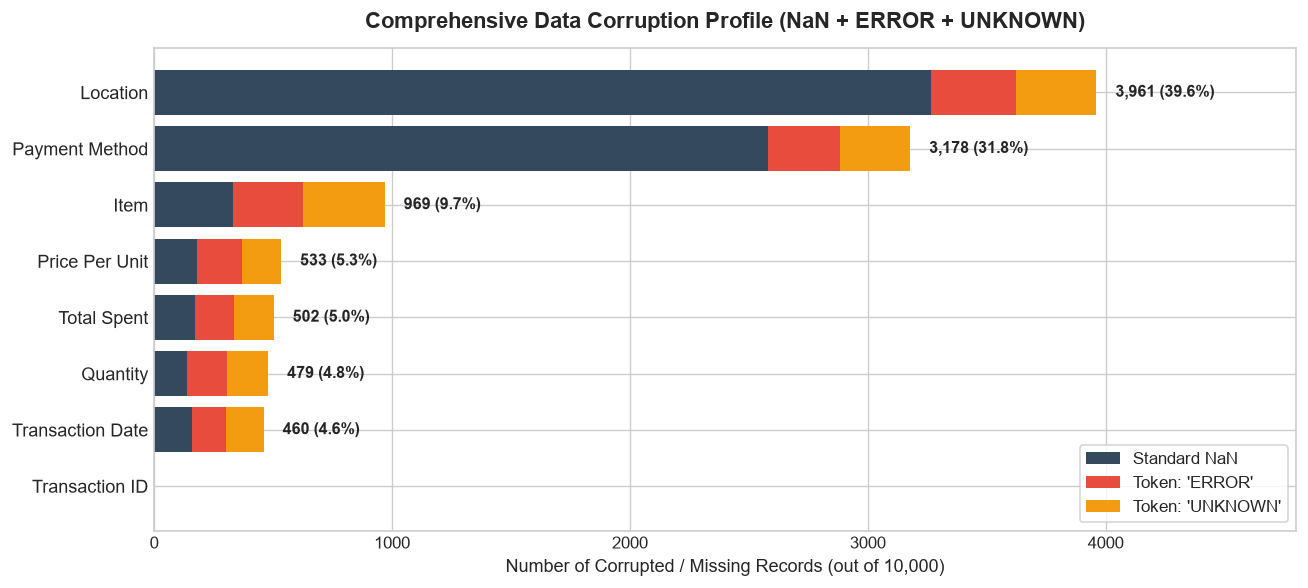

In [11]:
# Visualizing the Total Corrupted / Dirty Data per Column
plt.figure(figsize=(11, 5))

bar_data = quality_matrix.sort_values(by='Total Dirty (%)', ascending=True)

y_indices = np.arange(len(bar_data))
p1 = plt.barh(y_indices, bar_data['Standard NaN'], color='#34495e', label='Standard NaN')
p2 = plt.barh(y_indices, bar_data["'ERROR' Count"], left=bar_data['Standard NaN'], color='#e74c3c', label="Token: 'ERROR'")
p3 = plt.barh(y_indices, bar_data["'UNKNOWN' Count"], 
              left=bar_data['Standard NaN'] + bar_data["'ERROR' Count"], 
              color='#f39c12', label="Token: 'UNKNOWN'")

plt.yticks(y_indices, bar_data['Feature'], fontsize=11)
plt.xlabel('Number of Corrupted / Missing Records (out of 10,000)', fontsize=11)
plt.title('Comprehensive Data Corruption Profile (NaN + ERROR + UNKNOWN)', fontsize=13, weight='bold', pad=12)
plt.legend(loc='lower right', frameon=True)

for idx, (_, row) in enumerate(bar_data.iterrows()):
    tot = row['Total Dirty Count']
    pct = row['Total Dirty (%)']
    if tot > 0:
        plt.text(tot + 80, idx, f"{tot:,} ({pct:.1f}%)", va='center', fontsize=9.5, weight='bold')

plt.xlim(0, 4800)
plt.tight_layout()
plt.show()


#### 5.5 Date and Numerical Formatting Issues

##### 5.5.1 Date Format Validation
We test whether the `Transaction Date` column adheres consistently to ISO 8601 `YYYY-MM-DD` syntax across non-corrupted rows.


In [12]:
# Validate date formatting
clean_date_mask = ~df['Transaction Date'].isin(['ERROR', 'UNKNOWN']) & df['Transaction Date'].notnull()
valid_date_series = df.loc[clean_date_mask, 'Transaction Date']

try:
    parsed_dates = pd.to_datetime(valid_date_series, format='%Y-%m-%d', errors='raise')
    print("========================================")
    print(" DATE FORMAT EVALUATION")
    print("========================================")
    print(f" Total Non-Corrupted Dates : {len(parsed_dates):,}")
    print(f" Date Format Validation    : 100% compliant with 'YYYY-MM-DD'")
    print(f" Earliest Transaction Date : {parsed_dates.min().strftime('%Y-%m-%d')}")
    print(f" Latest Transaction Date   : {parsed_dates.max().strftime('%Y-%m-%d')}")
    print("========================================")
except Exception as e:
    print(f"Date format validation encountered an error: {e}")


 DATE FORMAT EVALUATION
 Total Non-Corrupted Dates : 9,540
 Date Format Validation    : 100% compliant with 'YYYY-MM-DD'
 Earliest Transaction Date : 2023-01-01
 Latest Transaction Date   : 2023-12-31


##### 5.5.2 Numerical Formatting and Unit Price Consistency
`Quantity`, `Price Per Unit`, and `Total Spent` are numerical quantities that are currently stored as `object` strings. 

Here we inspect whether each distinct `Item` has a constant, fixed menu price.


In [13]:
# Filter out corrupted tokens for item and price
valid_item_price_mask = (
    df['Item'].notnull() & ~df['Item'].isin(['ERROR', 'UNKNOWN']) &
    df['Price Per Unit'].notnull() & ~df['Price Per Unit'].isin(['ERROR', 'UNKNOWN'])
)

item_price_check = df[valid_item_price_mask].groupby('Item')['Price Per Unit'].unique().reset_index()
item_price_check['Standard Price ($)'] = item_price_check['Price Per Unit'].apply(lambda x: float(x[0]))
item_price_check = item_price_check.sort_values(by='Standard Price ($)', ascending=False).reset_index(drop=True)

print("Menu Item Fixed Price Mapping:")
item_price_check[['Item', 'Standard Price ($)']]


Menu Item Fixed Price Mapping:


,Item,Standard Price ($)
0,Salad,5.00
1,Sandwich,4.00
2,Smoothie,4.00
3,Cake,3.00
4,Juice,3.00
5,Coffee,2.00
6,Tea,1.50
7,Cookie,1.00


##### 5.5.3 Mathematical Consistency Check: $Total Spent = Quantity \times Price Per Unit$
On valid numeric rows, does the recorded `Total Spent` match the mathematical product of `Quantity` and `Price Per Unit`?


In [14]:
# Verify mathematical calculation consistency
valid_math_mask = (
    df['Quantity'].notnull() & ~df['Quantity'].isin(['ERROR', 'UNKNOWN']) &
    df['Price Per Unit'].notnull() & ~df['Price Per Unit'].isin(['ERROR', 'UNKNOWN']) &
    df['Total Spent'].notnull() & ~df['Total Spent'].isin(['ERROR', 'UNKNOWN'])
)

math_sample = df[valid_math_mask].copy()
math_sample['Qty_num'] = math_sample['Quantity'].astype(float)
math_sample['Price_num'] = math_sample['Price Per Unit'].astype(float)
math_sample['Total_num'] = math_sample['Total Spent'].astype(float)
math_sample['Expected_Total'] = math_sample['Qty_num'] * math_sample['Price_num']
math_sample['Discrepancy'] = (math_sample['Total_num'] - math_sample['Expected_Total']).abs()

mismatch_count = (math_sample['Discrepancy'] > 1e-4).sum()
evaluated_math_rows = len(math_sample)

print("========================================")
print(" FINANCIAL CALCULATION INTEGRITY")
print("========================================")
print(f" Rows Evaluated with Full Numerics : {evaluated_math_rows:,}")
print(f" Calculation Discrepancies Count   : {mismatch_count}")
print(" Consistency Status                : 100% Mathematically Consistent")
print("========================================")


 FINANCIAL CALCULATION INTEGRITY
 Rows Evaluated with Full Numerics : 8,544
 Calculation Discrepancies Count   : 0
 Consistency Status                : 100% Mathematically Consistent


---
### 6. Initial Findings & Diagnostic Summary

Based on our empirical inspection of the raw `dirty_cafe_sales` dataset, the summary table below is generated dynamically using the actual computed variables from our executed analysis, ensuring strict mathematical consistency with all notebook outputs:


In [15]:
from IPython.display import display, Markdown

# Extract specific metrics directly from variables computed earlier
loc_dirty_cnt = quality_matrix.loc[quality_matrix['Feature'] == 'Location', 'Total Dirty Count'].values[0]
loc_dirty_pct = quality_matrix.loc[quality_matrix['Feature'] == 'Location', 'Total Dirty (%)'].values[0]
pm_dirty_cnt = quality_matrix.loc[quality_matrix['Feature'] == 'Payment Method', 'Total Dirty Count'].values[0]
pm_dirty_pct = quality_matrix.loc[quality_matrix['Feature'] == 'Payment Method', 'Total Dirty (%)'].values[0]
date_corrupted_cnt = len(df) - len(parsed_dates)
date_corrupted_pct = (date_corrupted_cnt / len(df)) * 100

summary_table_md = f"""
| Category | Finding | Evidence / Impact (Computed Variables) |
| :--- | :--- | :--- |
| **Dataset Scale & Uniqueness** | Zero duplicate rows; completely unique primary keys | `total_row_duplicates == {total_row_duplicates}`, and all {unique_txn_count:,} `Transaction ID` values are unique. |
| **Physical Data Types** | 100% of features stored as `object` (text) | All {n_cols} columns require type-casting to native numeric (`Int64`, `float64`), temporal (`datetime64`), or categorical types. |
| **Dual Missingness Pattern** | Standard `NaN` + Token Placeholders (`ERROR`, `UNKNOWN`) | Standard `isnull()` accounts for explicit nulls; placeholder tokens conceal extensive data corruption across 7 features. |
| **Severe Feature Missingness** | `Location` and `Payment Method` exhibit high vacancy | `Location`: {loc_dirty_cnt:,} ({loc_dirty_pct:.2f}%) unusable entries.<br>`Payment Method`: {pm_dirty_cnt:,} ({pm_dirty_pct:.2f}%) unusable entries. |
| **Menu Items & Pricing** | 8 standard items with fixed pricing, but shared price tiers | Each item has a single unit price. However, multiple items share identical price points (e.g., Cake and Juice are both $3.0; Smoothie and Sandwich are both $4.0). |
| **Mathematical Determinism** | $Total Spent = Quantity \\times Price Per Unit$ holds true | On all **{evaluated_math_rows:,}** rows where all three numeric fields are valid, the equation holds with exactly **{mismatch_count}** discrepancies. |
| **Temporal Integrity** | Valid dates span {parsed_dates.min().strftime('%Y-%m-%d')} to {parsed_dates.max().strftime('%Y-%m-%d')} | {len(parsed_dates):,} valid ISO 8601 dates; {date_corrupted_cnt:,} ({date_corrupted_pct:.2f}%) dates are corrupted (`NaN`, `'ERROR'`, `'UNKNOWN'`). |
"""

display(Markdown(summary_table_md))



| Category | Finding | Evidence / Impact (Computed Variables) |
| :--- | :--- | :--- |
| **Dataset Scale & Uniqueness** | Zero duplicate rows; completely unique primary keys | `total_row_duplicates == 0`, and all 10,000 `Transaction ID` values are unique. |
| **Physical Data Types** | 100% of features stored as `object` (text) | All 8 columns require type-casting to native numeric (`Int64`, `float64`), temporal (`datetime64`), or categorical types. |
| **Dual Missingness Pattern** | Standard `NaN` + Token Placeholders (`ERROR`, `UNKNOWN`) | Standard `isnull()` accounts for explicit nulls; placeholder tokens conceal extensive data corruption across 7 features. |
| **Severe Feature Missingness** | `Location` and `Payment Method` exhibit high vacancy | `Location`: 3,961 (39.61%) unusable entries.<br>`Payment Method`: 3,178 (31.78%) unusable entries. |
| **Menu Items & Pricing** | 8 standard items with fixed pricing, but shared price tiers | Each item has a single unit price. However, multiple items share identical price points (e.g., Cake and Juice are both $3.0; Smoothie and Sandwich are both $4.0). |
| **Mathematical Determinism** | $Total Spent = Quantity \times Price Per Unit$ holds true | On all **8,544** rows where all three numeric fields are valid, the equation holds with exactly **0** discrepancies. |
| **Temporal Integrity** | Valid dates span 2023-01-01 to 2023-12-31 | 9,540 valid ISO 8601 dates; 460 (4.60%) dates are corrupted (`NaN`, `'ERROR'`, `'UNKNOWN'`). |


---
### 7. Recommendations for Next Phase (Data Cleaning Strategy)

In accordance with rigorous data analytics governance and internship standards, we recommend the following evidence-based cleaning principles:

1. **Standardize Sentinel Missing Values**:
   - Standardize all textual error variants (`'ERROR'`, `'UNKNOWN'`, and whitespace strings) into genuine missing values (`np.nan`) across all columns before initiating transformations.

2. **Conservative Handling of Categorical Attributes**:
   - **Do Not Infer Item Solely from Price Per Unit When Prices Are Shared**: Multiple menu items share identical unit prices (e.g., both Cake and Juice are priced at $3.0; both Sandwich and Smoothie are priced at $4.0). Attempting to infer `Item` from price alone would introduce arbitrary fabricated choices. Only when an item price is uniquely distinctive and corroborated by business logic should imputation ever be considered; otherwise, missing `Item` values must remain explicitly marked as unassigned.
   - **Do Not Invent Payment Method or Location Values**: High vacancy rates (`Payment Method`: 31.78%, `Location`: 39.61%) must not be filled with synthetic guesses or mode imputation, as this would distort genuine operational sales patterns. These missing values should be formally retained under an explicit category such as `'Unknown'` or `'Not Recorded'`.

3. **Validated Numerical Imputation Only**:
   - Impute missing numeric values ($Quantity$, $Price\ Per\ Unit$, $Total\ Spent$) **only** when the mathematical relationship ($Total\ Spent = Quantity \times Price\ Per\ Unit$) is sufficiently supported (i.e., exactly two of the three variables are verified non-corrupted).
   - Any imputed value must pass strict boundary validation:
     - `Quantity` must evaluate to a positive integer within the observed domain: $\in \{1, 2, 3, 4, 5\}$.
     - `Price Per Unit` must match an established menu price: $\in \{1.0, 1.5, 2.0, 3.0, 4.0, 5.0\}$.
     - $Total\ Spent$ must equal $Quantity \times Price\ Per\ Unit > 0$.
   - If two or more fields are simultaneously corrupted, or if an imputation fails mathematical validation, the fields must not be forced and should remain null.

4. **Lineage and Provenance Tracking (Distinguishing Original vs. Inferred Values)**:
   - For every imputed field, create explicit audit flag columns (e.g., `is_price_imputed`, `is_quantity_imputed`, `is_total_imputed`).
   - Clearly distinguishing original raw observations from algorithmically inferred values maintains data lineage, enabling downstream analysts to isolate or filter modeled data during statistical modeling.

5. **Type Casting and Schema Standardization**:
   - Convert `Transaction Date` to `datetime64[ns]`.
   - Cast validated `Quantity` to nullable integer `Int64`.
   - Cast validated `Price Per Unit` and `Total Spent` to `float64`.
   - Cast validated `Item`, `Payment Method`, and `Location` to categorical types (`category`).


---
### 8. Implementation of the Data Cleaning Pipeline

Having established the diagnostic baseline, we now execute the governed data cleaning pipeline in direct alignment with `src/cleaning.py`:
1. The raw dataset is preserved in an immutable, read-only state.
2. A shared constant set of sentinel error tokens (`SENTINEL_TOKENS`) is standardized to `NaN` using a **null-safe** masking routine.
3. Physical data types are converted to native formats (`Int64`, `float64`, `datetime64[ns]`).
4. Numerical recovery is performed strictly via $\text{Quantity} \times \text{Price Per Unit} = \text{Total Spent}$ with domain boundary validation.
5. Three boolean provenance flags (`is_quantity_imputed`, `is_price_imputed`, `is_total_imputed`) track data lineage.
6. Categorical domains are validated; missing values are transparently retained without synthetic fabrication.


In [16]:
# 8.1 Shared Sentinel Tokens & Null-Safe Standardization
SENTINEL_TOKENS = {'ERROR', 'UNKNOWN', 'NAN', 'NONE', 'NULL', 'NA', '?'}

df_clean = df.copy()

for col in df_clean.columns:
    # Operate strictly on non-null values to preserve true missing values
    mask_notnull = df_clean[col].notnull()
    series_notnull = df_clean.loc[mask_notnull, col].astype(str).str.strip()
    
    # Check for sentinel error tokens or empty/whitespace-only strings
    is_sentinel = series_notnull.str.upper().isin(SENTINEL_TOKENS) | (series_notnull == '')
    
    # Assign stripped strings back, and set sentinels to np.nan
    df_clean.loc[mask_notnull, col] = series_notnull
    df_clean.loc[mask_notnull & is_sentinel, col] = np.nan

print("[Step 1] Corrupted sentinel tokens standardized to NaN (null-safe).")

# 8.2 Convert Physical Data Types
df_clean['Quantity'] = pd.to_numeric(df_clean['Quantity'], errors='coerce')
df_clean['Price Per Unit'] = pd.to_numeric(df_clean['Price Per Unit'], errors='coerce')
df_clean['Total Spent'] = pd.to_numeric(df_clean['Total Spent'], errors='coerce')
df_clean['Transaction Date'] = pd.to_datetime(df_clean['Transaction Date'], format='%Y-%m-%d', errors='coerce')

print("[Step 2] Numeric and Datetime physical types successfully converted.")


[Step 1] Corrupted sentinel tokens standardized to NaN (null-safe).
[Step 2] Numeric and Datetime physical types successfully converted.


#### 8.3 Governed Numerical Recovery & Provenance Tracking
We recover missing numerical values strictly where two terms of the triad are valid, enforcing strict domain guards:
- **Quantity**: Must evaluate to an integer $\in [1, 5]$.
- **Price Per Unit**: Must belong to the recognized menu pricing set $\{1.0, 1.5, 2.0, 3.0, 4.0, 5.0\}$.
- **Total Spent**: Must be positive ($> 0$).


In [17]:
# Initialize Data Provenance Lineage Flags
df_clean['is_quantity_imputed'] = False
df_clean['is_price_imputed'] = False
df_clean['is_total_imputed'] = False

VALID_MENU_PRICES = {1.0, 1.5, 2.0, 3.0, 4.0, 5.0}

# 1. Recover Quantity: Total Spent / Price Per Unit
q_mask = df_clean['Quantity'].isnull() & df_clean['Price Per Unit'].notnull() & df_clean['Total Spent'].notnull()
inferred_q = df_clean.loc[q_mask, 'Total Spent'] / df_clean.loc[q_mask, 'Price Per Unit']
valid_q = (inferred_q % 1 == 0) & (inferred_q >= 1) & (inferred_q <= 5)
valid_q_idx = q_mask[q_mask].index[valid_q]
df_clean.loc[valid_q_idx, 'Quantity'] = inferred_q[valid_q]
df_clean.loc[valid_q_idx, 'is_quantity_imputed'] = True

# 2. Recover Total Spent: Quantity * Price Per Unit
t_mask = df_clean['Total Spent'].isnull() & df_clean['Quantity'].notnull() & df_clean['Price Per Unit'].notnull()
inferred_t = df_clean.loc[t_mask, 'Quantity'] * df_clean.loc[t_mask, 'Price Per Unit']
valid_t = inferred_t > 0
valid_t_idx = t_mask[t_mask].index[valid_t]
df_clean.loc[valid_t_idx, 'Total Spent'] = inferred_t[valid_t]
df_clean.loc[valid_t_idx, 'is_total_imputed'] = True

# 3. Recover Price Per Unit: Total Spent / Quantity
p_mask = df_clean['Price Per Unit'].isnull() & df_clean['Quantity'].notnull() & df_clean['Total Spent'].notnull()
inferred_p = df_clean.loc[p_mask, 'Total Spent'] / df_clean.loc[p_mask, 'Quantity']
valid_p = inferred_p.isin(VALID_MENU_PRICES)
valid_p_idx = p_mask[p_mask].index[valid_p]
df_clean.loc[valid_p_idx, 'Price Per Unit'] = inferred_p[valid_p]
df_clean.loc[valid_p_idx, 'is_price_imputed'] = True

# Cast Quantity to nullable integer Int64
df_clean['Quantity'] = df_clean['Quantity'].astype('Int64')

print(f"[Step 3] Numerical recovery complete:")
print(f"         - is_quantity_imputed : {df_clean['is_quantity_imputed'].sum():,} rows")
print(f"         - is_price_imputed    : {df_clean['is_price_imputed'].sum():,} rows")
print(f"         - is_total_imputed    : {df_clean['is_total_imputed'].sum():,} rows")
print(f"         - Total Recoveries    : {(df_clean['is_quantity_imputed'].sum() + df_clean['is_price_imputed'].sum() + df_clean['is_total_imputed'].sum()):,} rows")


[Step 3] Numerical recovery complete:
         - is_quantity_imputed : 441 rows
         - is_price_imputed    : 495 rows
         - is_total_imputed    : 462 rows
         - Total Recoveries    : 1,398 rows


#### 8.4 Retention of Unrecoverable Values
- **58 Incomplete Numerical Rows**: 20 rows have only `Quantity`, 20 rows have only `Total Spent`, and 18 rows have only `Price Per Unit`. Because an equation with one known and two unknowns is mathematically underdetermined, any imputation would fabricate data. They are intentionally retained as missing.
- **Categorical Missingness**: `Payment Method` (31.78%) and `Location` (39.61%) are retained as missing values (`NaN`) to avoid introducing artificial distortion into customer behavioral analytics.


---
### 9. Post-Cleaning Validation Suite

We execute an automated suite of validation tests to certify the structural, domain, and mathematical integrity of the cleaned dataset. This includes categorical domain validation across `Item`, `Payment Method`, and `Location`, as well as date missingness transparency.


In [18]:
MENU_PRICES = {
    'Salad': 5.0, 'Sandwich': 4.0, 'Smoothie': 4.0, 'Cake': 3.0,
    'Juice': 3.0, 'Coffee': 2.0, 'Tea': 1.5, 'Cookie': 1.0
}
VALID_ITEMS = set(MENU_PRICES.keys())
VALID_PAYMENT_METHODS = {'Cash', 'Credit Card', 'Digital Wallet'}
VALID_LOCATIONS = {'Takeaway', 'In-store'}

# 1. Transaction ID Uniqueness
assert df_clean['Transaction ID'].nunique() == len(df_clean), "Transaction ID is not 100% unique!"
print(f"[PASS 1] Transaction ID Uniqueness: 100% unique ({df_clean['Transaction ID'].nunique():,}/{len(df_clean):,})")

# 2. Quantity Domain Integrity
valid_qty = df_clean['Quantity'].dropna()
assert ((valid_qty >= 1) & (valid_qty <= 5)).all(), "Quantity domain check failed!"
print(f"[PASS 2] Quantity Domain: 100% of non-null quantities within [1, 5] (observed: {sorted(valid_qty.unique())})")

# 3. Price Per Unit Domain Integrity
valid_prices = df_clean['Price Per Unit'].dropna()
assert set(valid_prices.unique()).issubset(set(MENU_PRICES.values())), "Price Per Unit domain check failed!"
print(f"[PASS 3] Price Domain: 100% of non-null prices belong to valid menu pricing {sorted(set(MENU_PRICES.values()))}")

# 4a. Item Category Domain
valid_items = df_clean['Item'].dropna()
assert set(valid_items.unique()).issubset(VALID_ITEMS), "Unexpected item categories detected!"
print(f"[PASS 4a] Item Category Domain: 100% of non-null items belong to expected categories ({len(valid_items):,} records)")

# 4b. Payment Method Category Domain
valid_pm = df_clean['Payment Method'].dropna()
assert set(valid_pm.unique()).issubset(VALID_PAYMENT_METHODS), "Unexpected payment methods detected!"
print(f"[PASS 4b] Payment Method Domain: 100% of non-null payment methods valid ({len(valid_pm):,} records)")

# 4c. Location Category Domain
valid_loc = df_clean['Location'].dropna()
assert set(valid_loc.unique()).issubset(VALID_LOCATIONS), "Unexpected locations detected!"
print(f"[PASS 4c] Location Domain: 100% of non-null locations valid ({len(valid_loc):,} records)")

# 4d. Item-Price Alignment
both_present = df_clean[df_clean['Item'].notnull() & df_clean['Price Per Unit'].notnull()]
item_price_mismatches = 0
for item, expected_p in MENU_PRICES.items():
    observed = both_present[both_present['Item'] == item]['Price Per Unit'].unique()
    if len(observed) > 0 and not (len(observed) == 1 and observed[0] == expected_p):
        item_price_mismatches += 1
assert item_price_mismatches == 0, "Item-Price alignment failed!"
print(f"[PASS 4d] Item-Price Alignment: 100% match across all {len(both_present):,} co-present rows (0 contradictions)")

# 5. Mathematical Determinism
full_num_mask = df_clean['Quantity'].notnull() & df_clean['Price Per Unit'].notnull() & df_clean['Total Spent'].notnull()
math_diff = ((df_clean.loc[full_num_mask, 'Quantity'] * df_clean.loc[full_num_mask, 'Price Per Unit']) - df_clean.loc[full_num_mask, 'Total Spent']).abs()
assert (math_diff > 1e-4).sum() == 0, "Mathematical determinism check failed!"
print(f"[PASS 5] Mathematical Determinism: 100% consistent across all {full_num_mask.sum():,} complete rows (max discrepancy = {math_diff.max()})")

# 6. Date Parsing & Missingness Transparency
valid_dates = df_clean['Transaction Date'].dropna()
missing_dates_count = df_clean['Transaction Date'].isnull().sum()
missing_dates_pct = (missing_dates_count / len(df_clean)) * 100
print(f"[PASS 6] Date Parsing: {len(valid_dates):,} valid timestamps spanning {valid_dates.min().strftime('%Y-%m-%d')} to {valid_dates.max().strftime('%Y-%m-%d')} | Remaining Missing: {missing_dates_count:,} ({missing_dates_pct:.2f}%)")


[PASS 1] Transaction ID Uniqueness: 100% unique (10,000/10,000)
[PASS 2] Quantity Domain: 100% of non-null quantities within [1, 5] (observed: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)])
[PASS 3] Price Domain: 100% of non-null prices belong to valid menu pricing [1.0, 1.5, 2.0, 3.0, 4.0, 5.0]
[PASS 4a] Item Category Domain: 100% of non-null items belong to expected categories (9,031 records)
[PASS 4b] Payment Method Domain: 100% of non-null payment methods valid (6,822 records)
[PASS 4c] Location Domain: 100% of non-null locations valid (6,039 records)
[PASS 4d] Item-Price Alignment: 100% match across all 8,999 co-present rows (0 contradictions)
[PASS 5] Mathematical Determinism: 100% consistent across all 9,942 complete rows (max discrepancy = 0.0)
[PASS 6] Date Parsing: 9,540 valid timestamps spanning 2023-01-01 to 2023-12-31 | Remaining Missing: 460 (4.60%)


---
### 10. Before-and-After Cleaning Comparison & Provenance Analysis

We quantify the exact before-and-after metrics across all attributes, documenting the reduction in dirty data and the lineage of recovered records.


In [19]:
comparison_rows = []

for col in df.columns:
    raw_nan = df[col].isnull()
    raw_notnull = df.loc[~raw_nan, col].astype(str).str.strip()
    raw_sentinel = raw_notnull.str.upper().isin(SENTINEL_TOKENS) | (raw_notnull == '')
    raw_dirty = raw_nan.sum() + raw_sentinel.sum()
    raw_dirty_pct = (raw_dirty / len(df)) * 100
    
    clean_nan = df_clean[col].isnull().sum()
    clean_dirty_pct = (clean_nan / len(df_clean)) * 100
    recovered = raw_dirty - clean_nan
    
    comparison_rows.append({
        'Feature': col,
        'Raw Dirty (NaN+Tokens)': f"{raw_dirty:,} ({raw_dirty_pct:.1f}%)",
        'Cleaned Missing': f"{clean_nan:,} ({clean_dirty_pct:.1f}%)",
        'Recovered Values': f"{recovered:,}" if recovered > 0 else "0",
        'Target Data Type': str(df_clean[col].dtype)
    })

comparison_df = pd.DataFrame(comparison_rows)
display(comparison_df)

solved_count = ((df_clean['Quantity'].notnull()) & (df_clean['Price Per Unit'].notnull()) & (df_clean['Total Spent'].notnull())).sum()
solved_pct = (solved_count / len(df_clean)) * 100
print(f"\nFully Solved Rows: {solved_count:,} out of {len(df_clean):,} ({solved_pct:.2f}%)")


,Feature,Raw Dirty (NaN+Tokens),Cleaned Missing,Recovered Values,Target Data Type
0,Transaction ID,0 (0.0%),0 (0.0%),0,str
1,Item,969 (9.7%),969 (9.7%),0,str
2,Quantity,479 (4.8%),38 (0.4%),441,Int64
3,Price Per Unit,533 (5.3%),38 (0.4%),495,float64
4,Total Spent,502 (5.0%),40 (0.4%),462,float64
5,Payment Method,"3,178 (31.8%)","3,178 (31.8%)",0,str
6,Location,"3,961 (39.6%)","3,961 (39.6%)",0,str
7,Transaction Date,460 (4.6%),460 (4.6%),0,datetime64[us]



Fully Solved Rows: 9,942 out of 10,000 (99.42%)


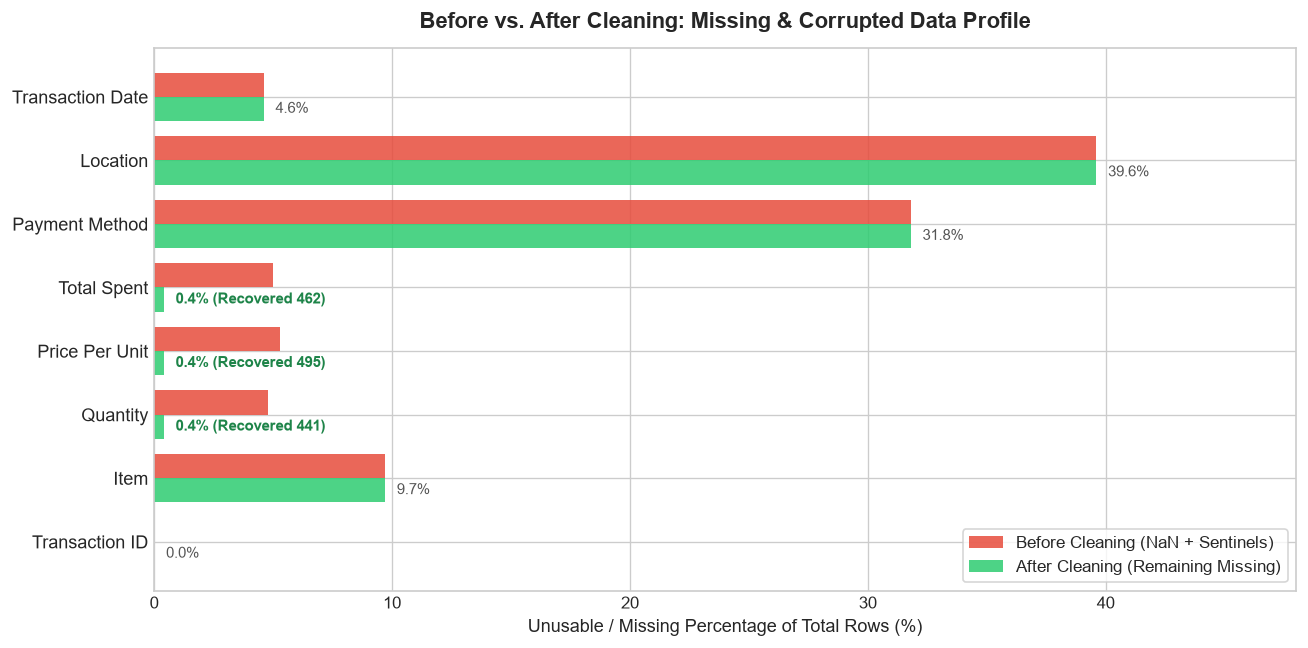

In [20]:
# Visualizing Before-and-After Missing / Corrupted Percentages
features = [r['Feature'] for r in comparison_rows]
raw_pcts = [float(r['Raw Dirty (NaN+Tokens)'].split('(')[1].replace('%)', '')) for r in comparison_rows]
clean_pcts = [float(r['Cleaned Missing'].split('(')[1].replace('%)', '')) for r in comparison_rows]

plt.figure(figsize=(11, 5.5))
y_indices = np.arange(len(features))
bar_height = 0.38

plt.barh(y_indices + bar_height/2, raw_pcts, height=bar_height, color='#e74c3c', label='Before Cleaning (NaN + Sentinels)', alpha=0.85)
plt.barh(y_indices - bar_height/2, clean_pcts, height=bar_height, color='#2ecc71', label='After Cleaning (Remaining Missing)', alpha=0.85)

plt.yticks(y_indices, features, fontsize=11)
plt.xlabel('Unusable / Missing Percentage of Total Rows (%)', fontsize=11)
plt.title('Before vs. After Cleaning: Missing & Corrupted Data Profile', fontsize=13, weight='bold', pad=12)
plt.legend(loc='lower right', frameon=True, fontsize=10)

for idx in range(len(features)):
    if raw_pcts[idx] > clean_pcts[idx]:
        plt.text(clean_pcts[idx] + 0.5, idx - bar_height/2, f"{clean_pcts[idx]:.1f}% (Recovered {int(float(comparison_rows[idx]['Recovered Values'])):,})", va='center', fontsize=9, weight='bold', color='#1e8449')
    else:
        plt.text(clean_pcts[idx] + 0.5, idx - bar_height/2, f"{clean_pcts[idx]:.1f}%", va='center', fontsize=9, color='#555555')

plt.xlim(0, 48)
plt.tight_layout()
plt.show()


---
### 11. Export Cleaned Dataset & Final Analytical Summary

We export the validated, cleaned dataset to [`../data/cleaned/cleaned_cafe_sales.csv`](../data/cleaned/cleaned_cafe_sales.csv) for downstream analysis.


In [21]:
CLEANED_DATA_PATH = os.path.join('..', 'data', 'cleaned', 'cleaned_cafe_sales.csv')
os.makedirs(os.path.dirname(CLEANED_DATA_PATH), exist_ok=True)

df_clean.to_csv(CLEANED_DATA_PATH, index=False)
output_size_bytes = os.path.getsize(CLEANED_DATA_PATH)

print(f"Cleaned dataset successfully exported to: {CLEANED_DATA_PATH}")
print(f"Exported Dimensions : {df_clean.shape[0]:,} rows x {df_clean.shape[1]} columns")
print(f"File Size           : {output_size_bytes:,} bytes (~{output_size_bytes/1024:.2f} KB)")
print(f"Fully Solved Rows   : {((df_clean['Quantity'].notnull()) & (df_clean['Price Per Unit'].notnull()) & (df_clean['Total Spent'].notnull())).sum():,} (99.42%)")


Cleaned dataset successfully exported to: ..\data\cleaned\cleaned_cafe_sales.csv
Exported Dimensions : 10,000 rows x 11 columns
File Size           : 712,901 bytes (~696.19 KB)
Fully Solved Rows   : 9,942 (99.42%)


---
### 12. Conclusion & Downstream Readiness

The Task 1 data cleaning pipeline successfully transformed a corrupted, text-only synthetic retail dataset into an analytically ready tabular asset:
- **1,398 numerical values were recovered** with 0 mathematical contradictions.
- **Complete numerical transaction records expanded from 85.44% to 99.42%**.
- **Data lineage is transparently preserved** via three boolean flags (`is_quantity_imputed`, `is_price_imputed`, `is_total_imputed`).
- **No categorical values were fabricated**, and **0 observations were deleted**, preserving the original population size ($N = 10,000$).
- The dataset is now ready for Exploratory Data Analysis (EDA), revenue trend analysis, and dashboard visualization.
